In [1]:
import os, copy, json, time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
from torchvision.utils import make_grid
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from torchmetrics.image.fid import FrechetInceptionDistance

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
MODEL_NAME = "sparse_ae"
DATA_DIR = "data"
CKPT_DIR = "checkpoints"
FIG_DIR = "figures"
RESULTS_DIR = "results"
for d in (DATA_DIR, CKPT_DIR, FIG_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

BATCH_SIZE = 128
ORIGINAL_DIM = 28 * 28
HIDDEN_DIM = 256
LATENT_DIM = 64
SPARSITY_LAMBDA = 0.05
MAX_EPOCHS = 30
LEARN_RATE = 1e-3

In [3]:
train_raw = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
test_raw = datasets.FashionMNIST(DATA_DIR, train=False, download=True)
images = torch.cat([train_raw.data, test_raw.data]).unsqueeze(1).float() / 255.0
labels = torch.cat([train_raw.targets, test_raw.targets])
full = TensorDataset(images, labels)

n_train, n_val = int(0.8 * len(full)), int(0.1 * len(full))
n_test = len(full) - n_train - n_val
train_set, val_set, test_set = random_split(
    full, [n_train, n_val, n_test], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
test_targets = labels[torch.tensor(test_set.indices)]
VIS_IDX = [int(torch.nonzero(test_targets == c)[0]) for c in range(10)]
x_vis = torch.stack([test_set[i][0] for i in VIS_IDX])
x_a, x_b = x_vis[1:2], x_vis[9:10]
ALPHAS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
print(f"train={len(train_set)}  val={len(val_set)}  test={len(test_set)}")

train=56000  val=7000  test=7000


In [4]:
def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()


@torch.no_grad()
def reconstruction_metrics(reconstruct, loader):
    psnr = PeakSignalNoiseRatio(data_range=1.0).to(device)
    ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
    se, count = 0.0, 0
    for x, _ in loader:
        x = x.to(device)
        x_hat = reconstruct(x).clamp(0, 1)
        se += F.mse_loss(x_hat, x, reduction="sum").item()
        count += x.numel()
        psnr.update(x_hat, x)
        ssim.update(x_hat, x)
    return {"test_mse": se / count, "test_psnr": psnr.compute().item(), "test_ssim": ssim.compute().item()}


@torch.no_grad()
def compute_fid(generate, n_samples=len(test_set), batch=250):
    fid = FrechetInceptionDistance(feature=2048, normalize=True).to(device)
    for x, _ in test_loader:
        fid.update(x.to(device).repeat(1, 3, 1, 1), real=True)
    done = 0
    while done < n_samples:
        b = min(batch, n_samples - done)
        fid.update(generate(b).clamp(0, 1).repeat(1, 3, 1, 1), real=False)
        done += b
    return fid.compute().item()


@torch.no_grad()
def measure_latency(fn, n_warmup=5, n_runs=20):
    for _ in range(n_warmup):
        fn()
    sync()
    start = time.perf_counter()
    for _ in range(n_runs):
        fn()
    sync()
    return (time.perf_counter() - start) / n_runs * 1000


def show_grid(images, nrow, title=None):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    plt.figure(figsize=(grid.shape[2] / 40, grid.shape[1] / 40))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis("off")
    if title:
        plt.title(title)
    plt.show()


def plot_history(history, keys):
    plt.figure(figsize=(6, 3.5))
    for k in keys:
        plt.plot(range(1, len(history[k]) + 1), history[k], label=k)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.legend()
    plt.show()


def save_results(results, outputs):
    with open(os.path.join(RESULTS_DIR, f"{MODEL_NAME}.json"), "w") as f:
        json.dump(results, f, indent=2)
    torch.save(outputs, os.path.join(RESULTS_DIR, f"{MODEL_NAME}_outputs.pt"))


def print_results(results):
    print(json.dumps({k: v for k, v in results.items() if k != "loss_history"}, indent=2))


x_latency = next(iter(test_loader))[0][:64].to(device)

In [5]:
class SparseEncoder(nn.Module):
    def __init__(self, hidden_dim, latent_dim):
        super().__init__()
        self.hidden_layer = nn.Linear(ORIGINAL_DIM, hidden_dim)
        self.latent_layer = nn.Linear(hidden_dim, latent_dim)

    def forward(self, input_features):
        h = F.relu(self.hidden_layer(input_features.flatten(1)))
        return self.latent_layer(h), h


class Decoder(nn.Module):
    def __init__(self, hidden_dim, latent_dim):
        super().__init__()
        self.hidden_layer = nn.Linear(latent_dim, hidden_dim)
        self.output_layer = nn.Linear(hidden_dim, ORIGINAL_DIM)

    def forward(self, encoded):
        h = F.relu(self.hidden_layer(encoded))
        return torch.sigmoid(self.output_layer(h)).view(-1, 1, 28, 28)


class SparseAutoencoder(nn.Module):
    def __init__(self, hidden_dim, latent_dim):
        super().__init__()
        self.encoder = SparseEncoder(hidden_dim, latent_dim)
        self.decoder = Decoder(hidden_dim, latent_dim)
        self.loss_history = []
        self.recon_history = []
        self.l1_history = []
        self.val_history = []

    def forward(self, input_features):
        encoded, hidden = self.encoder(input_features)
        return self.decoder(encoded), hidden

In [6]:
def sparse_ae_loss(preds, real, hidden):
    recon_error = torch.mean((preds - real) ** 2)
    l1_penalty = torch.mean(torch.abs(hidden))
    return recon_error + SPARSITY_LAMBDA * l1_penalty, recon_error, l1_penalty


def train(model, optimizer, original):
    preds, hidden = model(original)
    loss, recon_error, l1_penalty = sparse_ae_loss(preds, original, hidden)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return loss.item(), recon_error.item(), l1_penalty.item()


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_list = []
    for x, _ in loader:
        x = x.to(device)
        preds, hidden = model(x)
        loss_list.append(sparse_ae_loss(preds, x, hidden)[0].item())
    return np.mean(loss_list)


def train_ae_loop(model, opt, loader, epochs):
    epoch_times = []
    best_val, best_state = float("inf"), None
    for epoch in range(epochs):
        model.train()
        loss_list, recon_list, l1_list = [], [], []
        sync()
        start = time.perf_counter()
        for x, _ in loader:
            loss, recon_error, l1_penalty = train(model, opt, x.to(device))
            loss_list.append(loss)
            recon_list.append(recon_error)
            l1_list.append(l1_penalty)
        sync()
        epoch_times.append(time.perf_counter() - start)

        model.loss_history.append(np.mean(loss_list))
        model.recon_history.append(np.mean(recon_list))
        model.l1_history.append(np.mean(l1_list))
        model.val_history.append(evaluate(model, val_loader))
        if model.val_history[-1] < best_val:
            best_val, best_state = model.val_history[-1], copy.deepcopy(model.state_dict())

        print(f"Epoch[{epoch + 1} / {epochs}], Loss : {model.loss_history[-1]:.6f}, "
              f"Recon : {model.recon_history[-1]:.6f}, L1 : {model.l1_history[-1]:.4f}, "
              f"Val Loss : {model.val_history[-1]:.6f}, Time : {epoch_times[-1]:.1f}s")
    model.load_state_dict(best_state)
    return epoch_times

In [7]:
sae = SparseAutoencoder(HIDDEN_DIM, LATENT_DIM).to(device)
sae_optimizer = torch.optim.Adam(sae.parameters(), lr=LEARN_RATE)
print(sae)

epoch_times = train_ae_loop(sae, sae_optimizer, train_loader, MAX_EPOCHS)
torch.save(sae.state_dict(), os.path.join(CKPT_DIR, f"{MODEL_NAME}.pt"))
history = {"train_loss": [float(v) for v in sae.loss_history],
           "train_recon": [float(v) for v in sae.recon_history],
           "train_l1": [float(v) for v in sae.l1_history],
           "val_loss": [float(v) for v in sae.val_history]}

SparseAutoencoder(
  (encoder): SparseEncoder(
    (hidden_layer): Linear(in_features=784, out_features=256, bias=True)
    (latent_layer): Linear(in_features=256, out_features=64, bias=True)
  )
  (decoder): Decoder(
    (hidden_layer): Linear(in_features=64, out_features=256, bias=True)
    (output_layer): Linear(in_features=256, out_features=784, bias=True)
  )
)


Epoch[1 / 30], Loss : 0.048055, Recon : 0.046459, L1 : 0.0319, Val Loss : 0.029039, Time : 1.2s


Epoch[2 / 30], Loss : 0.026066, Recon : 0.024659, L1 : 0.0281, Val Loss : 0.024586, Time : 1.0s


Epoch[3 / 30], Loss : 0.023222, Recon : 0.021988, L1 : 0.0247, Val Loss : 0.022393, Time : 0.9s


Epoch[4 / 30], Loss : 0.021428, Recon : 0.020241, L1 : 0.0237, Val Loss : 0.020957, Time : 1.0s


Epoch[5 / 30], Loss : 0.020317, Recon : 0.019190, L1 : 0.0226, Val Loss : 0.020269, Time : 1.0s


... (21 outputs left out)

Epoch[27 / 30], Loss : 0.014921, Recon : 0.014115, L1 : 0.0161, Val Loss : 0.015379, Time : 1.1s


Epoch[28 / 30], Loss : 0.014910, Recon : 0.014106, L1 : 0.0161, Val Loss : 0.015334, Time : 1.1s


Epoch[29 / 30], Loss : 0.014833, Recon : 0.014035, L1 : 0.0160, Val Loss : 0.015278, Time : 1.1s


Epoch[30 / 30], Loss : 0.014732, Recon : 0.013943, L1 : 0.0158, Val Loss : 0.015459, Time : 1.1s


In [8]:
sae.eval()
results = {"model": MODEL_NAME, "latent_dim": LATENT_DIM, "sparse_hidden": HIDDEN_DIM,
           "sparsity_lambda": SPARSITY_LAMBDA,
           "train_time_per_epoch_s": float(np.mean(epoch_times))}
results.update(reconstruction_metrics(lambda x: sae(x)[0], test_loader))
results["latency_ms_batch64"] = measure_latency(lambda: sae(x_latency))
with torch.no_grad():
    hidden = torch.cat([sae.encoder(x.to(device))[1] for x, _ in test_loader])
results["hidden_zero_fraction"] = (hidden <= 1e-3).float().mean().item()
results["hidden_mean_activation"] = hidden.mean().item()
results["fid"] = None
results["loss_history"] = history
print_results(results)

{
  "model": "sparse_ae",
  "latent_dim": 64,
  "sparse_hidden": 256,
  "sparsity_lambda": 0.05,
  "train_time_per_epoch_s": 1.0488663400000102,
  "test_mse": 0.014360159893425144,
  "test_psnr": 18.42840576171875,
  "test_ssim": 0.74323570728302,
  "latency_ms_batch64": 0.2608999999893058,
  "hidden_zero_fraction": 0.9595742225646973,
  "hidden_mean_activation": 0.016209447756409645,
  "fid": null
}


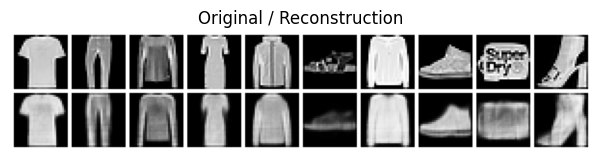

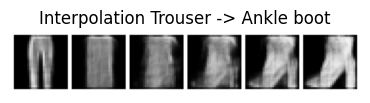

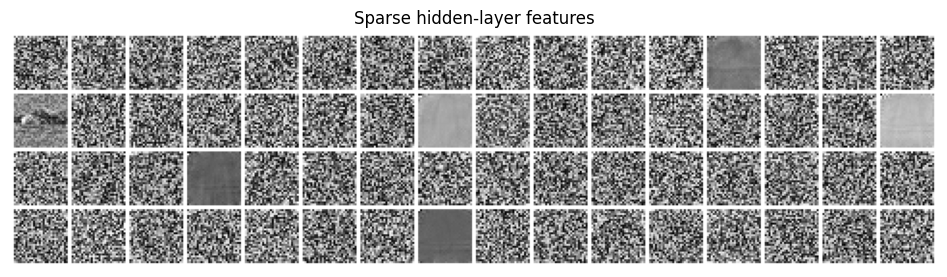

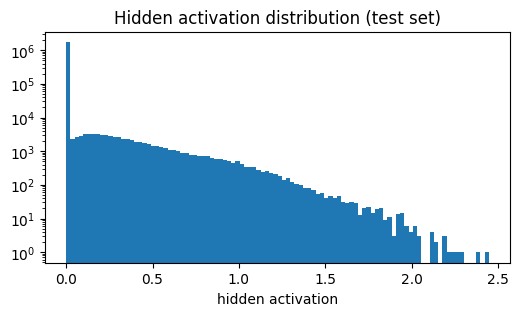

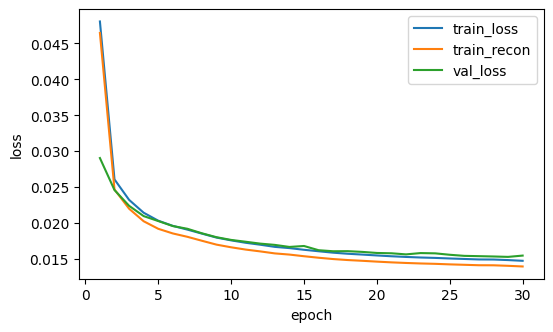

In [9]:
def normalize_filters(w):
    w = w.detach().cpu()
    w_min, w_max = w.min(1, keepdim=True)[0], w.max(1, keepdim=True)[0]
    return ((w - w_min) / (w_max - w_min + 1e-8)).view(-1, 1, 28, 28)

with torch.no_grad():
    recon = sae(x_vis.to(device))[0].cpu()
    z_a, z_b = sae.encoder(x_a.to(device))[0], sae.encoder(x_b.to(device))[0]
    interp = sae.decoder(torch.cat([(1 - a) * z_a + a * z_b for a in ALPHAS])).cpu()
features = normalize_filters(sae.encoder.hidden_layer.weight[:64])

show_grid(torch.cat([x_vis, recon]), nrow=10, title="Original / Reconstruction")
show_grid(interp, nrow=len(ALPHAS), title="Interpolation Trouser -> Ankle boot")
show_grid(features, nrow=16, title="Sparse hidden-layer features")
plt.figure(figsize=(6, 3))
plt.hist(hidden.flatten().cpu().numpy(), bins=100, log=True)
plt.xlabel("hidden activation")
plt.title("Hidden activation distribution (test set)")
plt.show()
plot_history(history, ["train_loss", "train_recon", "val_loss"])

In [10]:
save_results(results, {"recon": recon, "interp": interp, "features": features})